# EntryInterface: random signal to random RUL signal

This notebook runs a minimal `EntryInterface` training/evaluation loop with a synthetic RUL-style task. The input features are random signals, and the target `rul` is also a random signal. The goal is to exercise the interface, dataset creation, model training, and test evaluation path, not to learn a meaningful physical degradation pattern.

In [1]:
import logging

import numpy as np
import pandas as pd

from picid.data.data_objects.validation import (
    collect_split_alignment_report,
    format_split_alignment_report,
)
from picid.data.preprocessing import TimeSplitter
from picid.interface import CustomSingleSourceLoader, EntryInterface
from picid.interface.schemas.task_definition import Prognostic
from picid.transforms.base import DataTransform
from picid.transforms.base_transforms.scaler import MinMaxScalerSklearn
from picid.transforms.base_transforms.stfft import STFTTransform

logging.getLogger("picid.interface.interface").setLevel(logging.WARNING)
logging.getLogger("picid.interface.datasources").setLevel(logging.WARNING)
logging.getLogger("picid.data.datasets.hydra_concat_dataset").setLevel(logging.WARNING)


/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This m

Create one synthetic time-series source. `CustomSingleSourceLoader` expects the target to be one column in the table, so `rul` is stored as the last column.

In [2]:
SEED = 7
SEQ_LEN = 12
N_STEPS = 240
N_FEATURES = 3

rng = np.random.default_rng(SEED)

features = rng.normal(size=(N_STEPS, N_FEATURES)).astype(np.float32)
rul = rng.normal(size=(N_STEPS, 1)).astype(np.float32)

columns = [f"signal_{i}" for i in range(N_FEATURES)] + ["rul"]
frame = pd.DataFrame(np.concatenate([features, rul], axis=1), columns=columns)
frame.head()

,signal_0,signal_1,signal_2,rul
0,0.001230,0.298746,-0.274138,-0.604510
1,-0.890592,-0.454671,-0.991647,-0.341574
2,0.060144,1.340215,-0.492207,-2.309521
3,-0.620475,0.489842,0.356887,1.216947
4,0.105414,-0.930468,-0.029252,0.253346


Build a PICID datasource and preprocess it through the interface. The splitter uses the same `seq_len` as the prognostics task definition below, and `pred_len=0` matches RUL prediction. Two `DataTransform` steps are wired in programmatically: a `MinMaxScalerSklearn` fitted on the train split that scales the input features in place, and an `STFTTransform` that produces a side-channel `stft_features` key so the spectral output coexists with the original time-domain features.

In [3]:
splitter = TimeSplitter(
    train=0.6,
    val=0.2,
    test=None,
    seq_len=SEQ_LEN,
    pred_len=0,
    create_splits_for=["features", "timestamps", "rul"],
)

datasource = CustomSingleSourceLoader.load_from_csv(
    source=frame,
    target_column="rul",
    task_mode="rul",
    data_splitter=splitter,
    data_name="random_signal_rul",
)

scaler_features = DataTransform(
    transform_name="scaler_features",
    transform=MinMaxScalerSklearn(),
    metadata={"apply_to": "features", "fit_on": "train"},
)

stft_features = DataTransform(
    transform_name="stft_features",
    transform=STFTTransform(win_len=16, hop=8, output_format="magnitude"),
    metadata={"apply_to": "features", "assign_to": "stft_features"},
)

transforms = [scaler_features, stft_features]

interface = EntryInterface()
processed = interface.process_datasource(datasource, transforms=transforms)

{
    split: {key: [arr.shape for arr in values] for key, values in processed.data_dict[split].items()}
    for split in ["train", "val", "test"]
}


INFO:root:[MemorizedFunc(func=<function InterfacePreProcessor.apply_transforms at 0x313a7cd60>, location=/Users/rtheiler/picid/cache)]: 
                        Querying apply_transforms with signature
                        apply_transforms(SplitDatasetContainer(features=[train,val,test]({'train': 1, 'val': 1, 'test': 1}), rul=[train,val,test]({'train': 1, 'val': 1, 'test': 1}), timestamps=[train,val,test]({'train': 1, 'val': 1, 'test': 1}), split_masks=[train,val,test]({'train': 1, 'val': 1, 'test': 1}), unit_cardinality=single_unit_per_split), 
[ <picid.transforms.base.data_transform.data_transform.DataTransform object at 0x313a86f90>,
None).

                        (argument hash 26f52c807c19339c656d8629500a64f7)

                        The store location is /Users/rtheiler/picid/cache/picid/interface/utils/InterfacePreProcessor/apply_transforms.



[Memory]0.0s, 0.0min    : Loading apply_transforms from /Users/rtheiler/picid/cache/picid/interface/utils/InterfacePreProcessor/apply_transforms/26f52c807c19339c656d8629500a64f7
____________________________________apply_transforms cache loaded - 0.0s, 0.0min


{'train': {'features': [(144, 3)],
  'rul': [(144, 1)],
  'timestamps': [(144,)],
  'split_masks': [(144,)],
  'stft_features': [(19, 27)],
  'unit_metadata': []},
 'val': {'features': [(60, 3)],
  'rul': [(60, 1)],
  'timestamps': [(60,)],
  'split_masks': [(60,)],
  'stft_features': [(9, 27)],
  'unit_metadata': []},
 'test': {'features': [(60, 3)],
  'rul': [(60, 1)],
  'timestamps': [(60,)],
  'split_masks': [(60,)],
  'stft_features': [(9, 27)],
  'unit_metadata': []}}

Inspect the split layout with `collect_split_alignment_report`. It walks every key/split pair in `processed.data_dict` and reports the unit counts, sample shapes, and whether each split's payloads share the same schema. The plot visualises the structured report: bars on the left show how many units each split holds per key, and the grid on the right colours each (key, split) cell by schema status (`homogeneous`, `heterogeneous`, `empty`).

+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| key           | splits         | unit_counts            | sample_shapes                             | schema_status                                        | sample_schema                            |
|---------------+----------------+------------------------+-------------------------------------------+------------------------------------------------------+------------------------------------------|
| features      | test,train,val | test=1, train=1, val=1 | test=(60, 3), train=(144, 3), val=(60, 3) | test=homogeneous, train=homogeneous, val=homogeneous | test=ndarray, train=ndarray, val=ndarray |
| rul           | test,train,val | test=1, train=1, val=1 | test=(60, 1), train=(144, 1), val=(60, 1) | test=homogeneous, train=homogeneous, val=homogeneous | test=ndarray, train=ndarray, val=ndarray |
| split_masks   | test,train,val | test=1, train=1, val=1 | test=(60,), train=(144,), val=(60,)       | test=homogeneous, train=homogeneous, val=homogeneous | test=ndarray, train=ndarray, val=ndarray |
| stft_features | test,train,val | test=1, train=1, val=1 | test=(9, 27), train=(19, 27), val=(9, 27) | test=homogeneous, train=homogeneous, val=homogeneous | test=ndarray, train=ndarray, val=ndarray |
| timestamps    | test,train,val | test=1, train=1, val=1 | test=(60,), train=(144,), val=(60,)       | test=homogeneous, train=homogeneous, val=homogeneous | test=ndarray, train=ndarray, val=ndarray |
| unit_metadata | test,train,val | test=0, train=0, val=0 | test=empty, train=empty, val=empty        | test=empty, train=empty, val=empty                   | test=-, train=-, val=-                   |
+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+

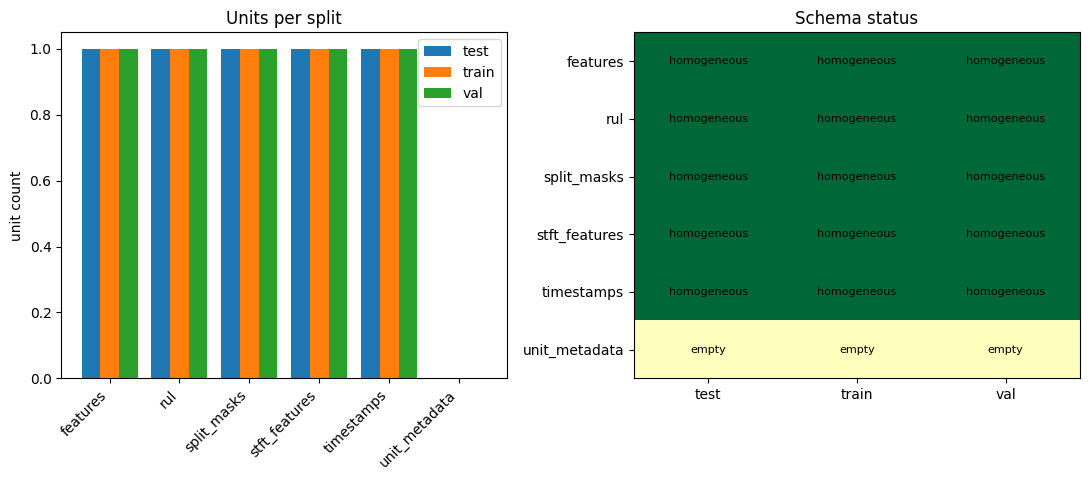

In [4]:
import matplotlib.pyplot as plt

data_dict = processed.data_dict

keys = sorted({k for split_data in data_dict.values() for k in split_data.keys()})
payloads = [
    (key, {split: data_dict[split].get(key, []) for split in data_dict})
    for key in keys
]

report = collect_split_alignment_report(payloads)
print(format_split_alignment_report(report))

splits = report["splits"]
report_keys = [row["key"] for row in report["rows"]]

status_to_int = {"empty": 0, "homogeneous": 1, "heterogeneous": -1}

fig, axes = plt.subplots(1, 2, figsize=(11, 0.4 * len(report_keys) + 2.5))

x = np.arange(len(report_keys))
width = 0.8 / max(len(splits), 1)
for i, split in enumerate(splits):
    counts = [(row["counts"][split] or 0) for row in report["rows"]]
    offset = (i - (len(splits) - 1) / 2) * width
    axes[0].bar(x + offset, counts, width, label=split)
axes[0].set_xticks(x)
axes[0].set_xticklabels(report_keys, rotation=45, ha="right")
axes[0].set_ylabel("unit count")
axes[0].set_title("Units per split")
axes[0].legend()

status_matrix = np.array(
    [[status_to_int[row["schema_status"][s]] for s in splits] for row in report["rows"]]
)
im = axes[1].imshow(status_matrix, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(splits)))
axes[1].set_xticklabels(splits)
axes[1].set_yticks(range(len(report_keys)))
axes[1].set_yticklabels(report_keys)
for i, row in enumerate(report["rows"]):
    for j, s in enumerate(splits):
        axes[1].text(j, i, row["schema_status"][s], ha="center", va="center", fontsize=8)
axes[1].set_title("Schema status")

plt.tight_layout()
plt.show()


Train a tiny MLP for one epoch and immediately evaluate on the test split. `+datasource.data_name=...` is required because a preprocessed custom datasource only injects `task_mode` automatically, while the model creation path still expects a datasource name. `datamodule.num_workers=0` keeps this notebook safe to run inside Jupyter.

In [5]:
task_definition = Prognostic(
    task_type="rul",
    seq_len=SEQ_LEN,
    stride=4,
    stride_train=4,
)

results = interface.train(
    run_name="entry_interface_random_signal_rul",
    model="mlp",
    task_definition=task_definition,
    datasource=processed,
    transforms=[],
    evaluators="default",
    # overrides=[
    #     # "+datasource.data_name=random_signal_rul",
    #     "logger=csv",
    #     "trainer.max_epochs=1",
    #     "trainer.accelerator=cpu",
    #     "trainer.devices=1",
    #     "datamodule.num_workers=0",
    #     "datamodule.train_batch_size=16",
    #     "datamodule.val_batch_size=16",
    #     "datamodule.test_batch_size=16",
    #     "enable_progress_bar=False",
    #     f"seed={SEED}",
    # ],
    enable_progress_bar=False,
    seed=SEED,
)

results

Seed set to 7


/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This m

/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This m

/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/Users/rtheiler/Workspaces/work/TabPHM/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This m

...

Restoring states from the checkpoint path at /Users/rtheiler/picid/eval_details/checkpoints/epoch082-val_loss3.60404253-v2.ckpt


Loaded model weights from the checkpoint at /Users/rtheiler/picid/eval_details/checkpoints/epoch082-val_loss3.60404253-v2.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/loss         │    1.7550219297409058     │
│    test/mae_normalized    │    1.0479035377502441     │
│    test/mse_normalized    │    1.7550220489501953     │
│   test/rmse_normalized    │    1.3247724771499634     │
└───────────────────────────┴───────────────────────────┘

[{'test/loss': 1.7550219297409058, 'test/mae_normalized': 1.0479035377502441, 'test/mse_normalized': 1.7550220489501953, 'test/rmse_normalized': 1.3247724771499634}]


[{'test/loss': 1.7550219297409058,
  'test/mae_normalized': 1.0479035377502441,
  'test/mse_normalized': 1.7550220489501953,
  'test/rmse_normalized': 1.3247724771499634}]

The returned object is the standard Lightning test result list. Because the target is random, the metric values only confirm that the pipeline ran end to end.